# Projeto 2, Sprint 1: Notebook 2
## Tempo de processamento de pagamentos PIX, Planilha 2 (depois da intervenção)

Este notebook responde às Questões 7.2, 7.3, 7.4 e 8 com os dados da Planilha 2, coletados depois da intervenção. Na Questão 8 também lemos a Planilha 1 (antes) para fazer a comparação.

Variável analisada: tempo de processamento do pagamento PIX, em segundos (s).

Importa as bibliotecas que vamos usar.

In [1]:
import pandas as pd
import numpy as np
import math
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm
import pylab

%config InlineBackend.figure_format = 'retina'

Define o nome do arquivo da planilha e o nome da coluna analisada.

In [2]:
arquivo = 'TEMPO PAGAMENTO PIX_planilha2_depois.xlsx'
coluna = 'Tempo_processamento_seg'

Lê a planilha e guarda os dados em `df`.

In [3]:
df = pd.read_excel(arquivo)
df

,Tempo_processamento_seg
0,1.47
1,1.48
2,1.61
3,1.67
4,1.69
...,...
295,3.40
296,3.40
297,3.41
298,3.42


In [4]:
df[coluna].describe().round(2)

count    300.00
mean       2.51
std        0.40
min        1.47
25%        2.23
50%        2.51
75%        2.77
max        3.45
Name: Tempo_processamento_seg, dtype: float64

A Planilha 2 tem 300 pagamentos PIX, com tempos entre 1,47 s e 3,45 s.

# Questão 7.2: Representação gráfica dos dados posteriores à intervenção

### a) Histograma

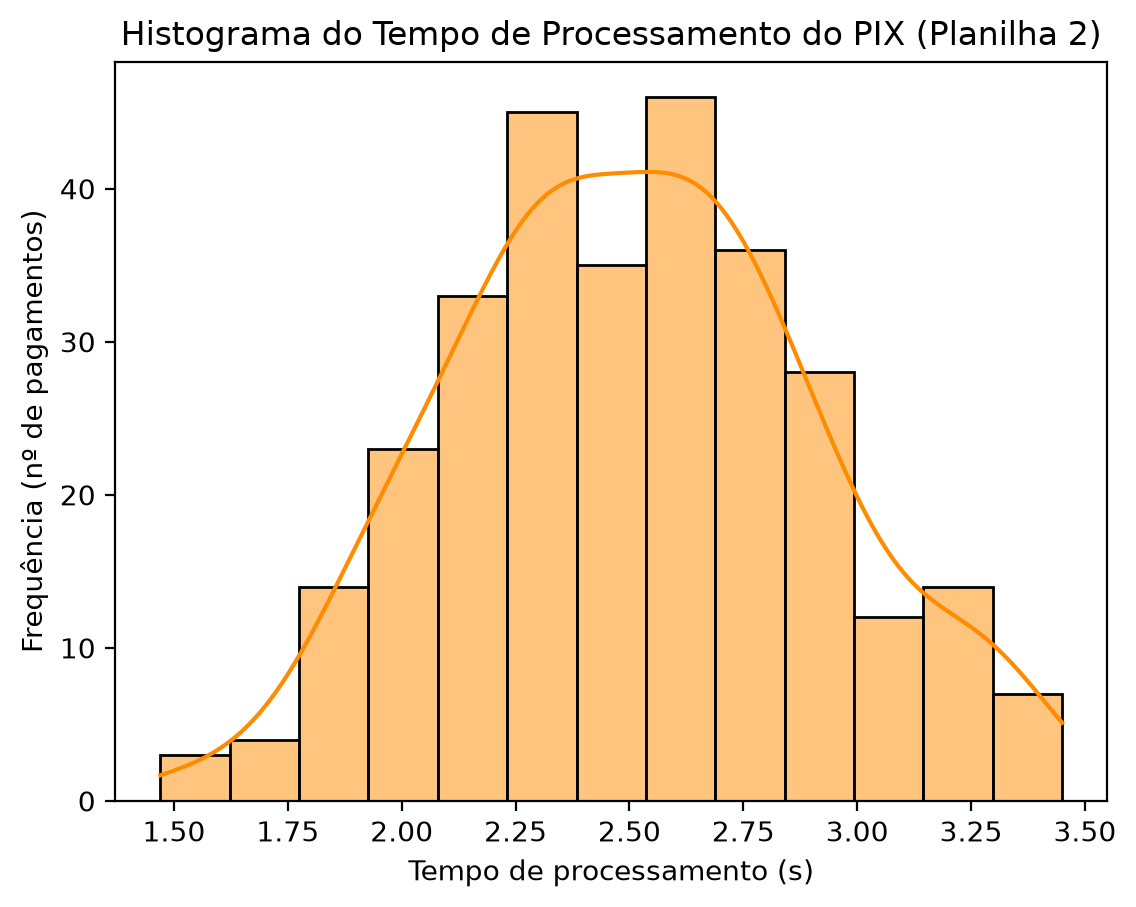

In [5]:
sns.histplot(data=df[coluna], kde=True, color='darkorange')
plt.title('Histograma do Tempo de Processamento do PIX (Planilha 2)')
plt.xlabel('Tempo de processamento (s)')
plt.ylabel('Frequência (nº de pagamentos)')
plt.show()

**Interpretação:** depois da intervenção os tempos ficaram concentrados entre 2 s e 3 s, com um pico só, perto de 2,5 s, e formato de sino. Nenhum pagamento passou de 3,5 s.

### b) Boxplot

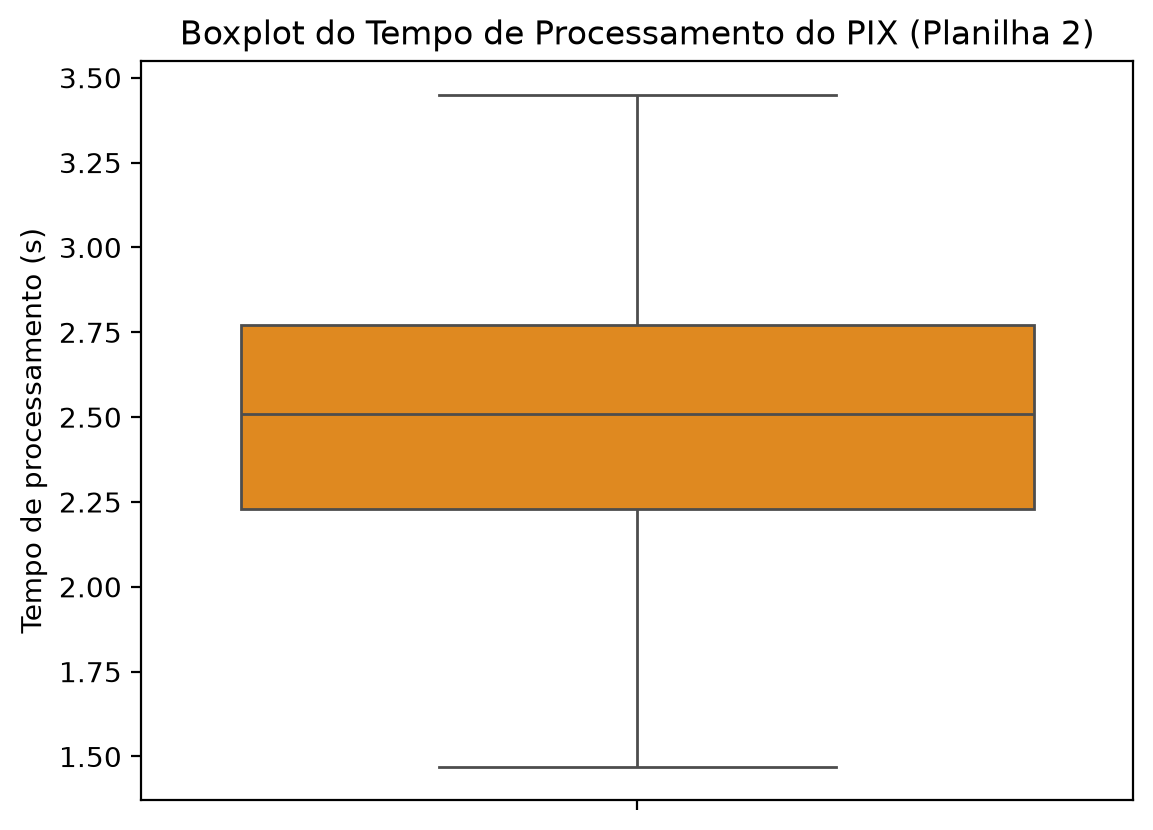

In [6]:
sns.boxplot(y=df[coluna], color='darkorange')
plt.title('Boxplot do Tempo de Processamento do PIX (Planilha 2)')
plt.ylabel('Tempo de processamento (s)')
plt.show()

**Interpretação:** a caixa vai de mais ou menos 2,2 s até 2,8 s, com a mediana em 2,5 s, quase no centro. A distribuição é simétrica, os bigodes são curtos e não tem outliers.

# Questão 7.3: Média e desvio padrão dos dados posteriores à intervenção

In [7]:
media = df[coluna].mean()
dpad = df[coluna].std()
mediana = df[coluna].median()

print(f'Média: {media:.2f} s')
print(f'Desvio padrão: {dpad:.2f} s')
print(f'Mediana: {mediana:.2f} s')

Média: 2.51 s
Desvio padrão: 0.40 s
Mediana: 2.51 s


**Interpretação:** depois da intervenção, um pagamento PIX leva em média 2,51 s para ser processado, com desvio padrão de 0,40 s. Os tempos ficaram menores e também mais parecidos entre si.

# Questão 7.4: Análise de um intervalo relacionado ao objetivo

Intervalo escolhido: [2 s, 4 s], a faixa de referência do mercado que já foi usada na Questão 5.

**Pergunta:** quantos dos 300 pagamentos PIX da Planilha 2 foram processados entre 2 s e 4 s, que é a faixa dos aplicativos de banco mais bem avaliados?

In [8]:
a = 2
b = 4
quantidade_ab = sum(i >= a and i <= b for i in df[coluna].sort_values())
porcentagem_ab = round((quantidade_ab/len(df[coluna]))*100, 2)

print(f'Pagamentos entre {a} s e {b} s: {quantidade_ab} de {len(df[coluna])} ({porcentagem_ab}%)')

Pagamentos entre 2 s e 4 s: 271 de 300 (90.33%)


In [9]:
print('Pagamentos abaixo de 2 s:', sum(i < a for i in df[coluna]))
print('Pagamentos acima de 4 s:', sum(i > b for i in df[coluna]))

Pagamentos abaixo de 2 s: 29
Pagamentos acima de 4 s: 0


**Resposta:** 271 dos 300 pagamentos (90,33%) da Planilha 2 foram processados entre 2 s e 4 s. Os outros 29 ficaram abaixo de 2 s, ou seja, foram até mais rápidos que a faixa de referência.

# Questão 8: Comparação entre os resultados

**Pergunta:** com base neste estudo, há indícios de que a reestruturação do fluxo de processamento do PIX foi eficaz para reduzir o tempo de pagamento no aplicativo?

Para comparar, lemos também a Planilha 1 (antes da intervenção):

In [10]:
arquivo_antes = 'TEMPO PAGAMENTO PIX_planilha1_antes.xlsx'
df_antes = pd.read_excel(arquivo_antes)

media_antes = df_antes[coluna].mean()
dpad_antes = df_antes[coluna].std()

### Critérios de comparação

- **Critério 1:** proporção de pagamentos processados em até 3 s, que é a meta ideal definida na Questão 7.1.
- **Critério 2:** proporção de pagamentos processados entre 2 s e 4 s, a faixa de referência do mercado (Questões 1, 5 e 7.4).

Para a Planilha 1 mostramos a probabilidade pelo modelo normal (igual na Questão 5) e também a proporção que aparece nos dados. Para a Planilha 2 usamos a proporção dos dados.

In [11]:
def proporcao(dados, a, b):
    return round(sum(i >= a and i <= b for i in dados)/len(dados)*100, 2)

def prob_normal(a, b):
    return round((norm.cdf(b, loc=media_antes, scale=dpad_antes) - norm.cdf(a, loc=media_antes, scale=dpad_antes))*100, 2)

comparacao = pd.DataFrame({
    'Critério': ['1) Até 3 s (meta ideal)', '2) Entre 2 s e 4 s (mercado)', 'Acima de 5 s (limite de tolerância)'],
    'Planilha 1, modelo normal (%)': [prob_normal(0, 3), prob_normal(2, 4), round(norm.sf(5, loc=media_antes, scale=dpad_antes)*100, 2)],
    'Planilha 1, observado (%)': [proporcao(df_antes[coluna], 0, 3), proporcao(df_antes[coluna], 2, 4), round((df_antes[coluna] > 5).mean()*100, 2)],
    'Planilha 2, observado (%)': [proporcao(df[coluna], 0, 3), proporcao(df[coluna], 2, 4), round((df[coluna] > 5).mean()*100, 2)]
})
comparacao

,Critério,"Planilha 1, modelo normal (%)","Planilha 1, observado (%)","Planilha 2, observado (%)"
0,1) Até 3 s (meta ideal),0.48,0.0,89.00
1,2) Entre 2 s e 4 s (mercado),8.76,9.0,90.33
2,Acima de 5 s (limite de tolerância),54.81,56.0,0.00


Resumo das medidas dos dois cenários e comparação nos gráficos:

In [12]:
resumo = pd.DataFrame({
    'Planilha 1 (antes)': [len(df_antes), round(media_antes, 2), round(df_antes[coluna].median(), 2), round(dpad_antes, 2)],
    'Planilha 2 (depois)': [len(df), round(media, 2), round(mediana, 2), round(dpad, 2)]
}, index=['Nº de pagamentos', 'Média (s)', 'Mediana (s)', 'Desvio padrão (s)'], dtype=object)
resumo

,Planilha 1 (antes),Planilha 2 (depois)
Nº de pagamentos,100,300
Média (s),5.1,2.51
Mediana (s),5.12,2.51
Desvio padrão (s),0.81,0.4


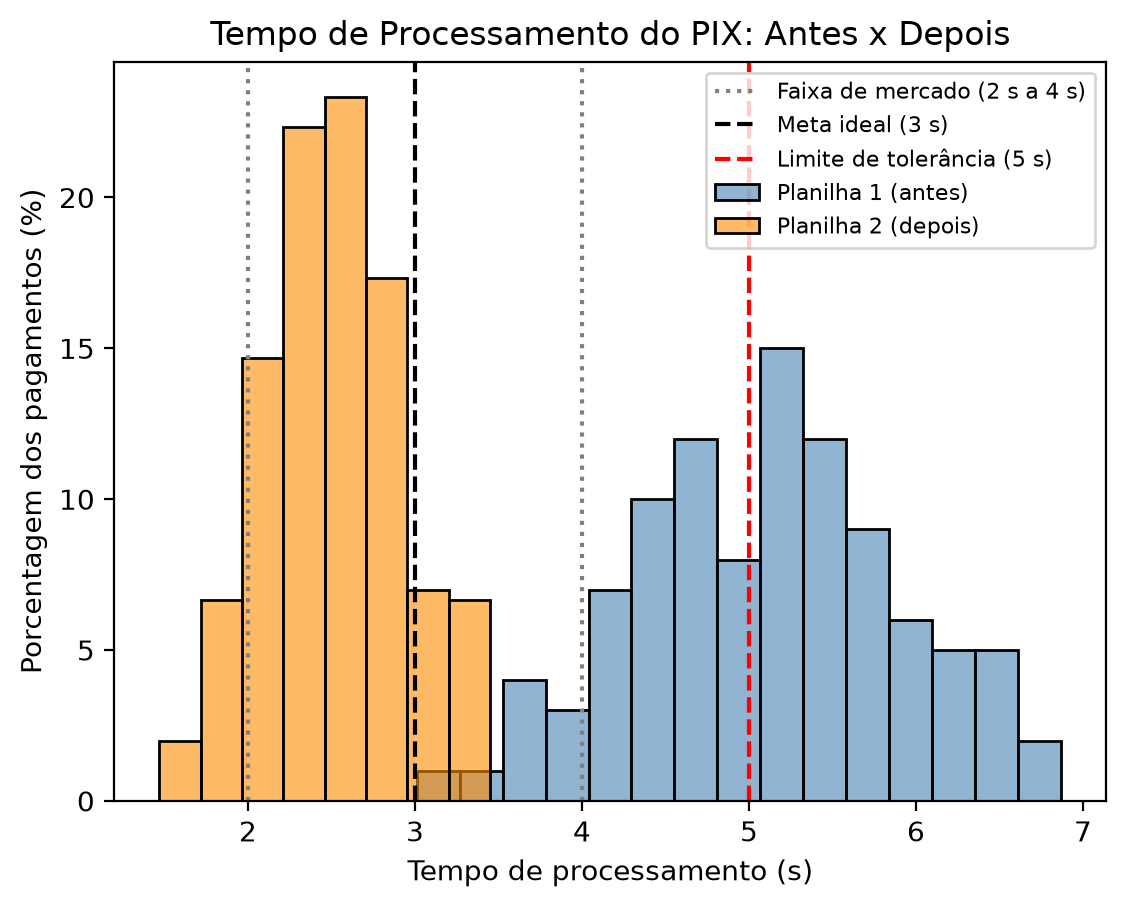

In [13]:
sns.histplot(data=df_antes[coluna], stat='percent', binwidth=0.25, color='steelblue', alpha=0.6, label='Planilha 1 (antes)')
sns.histplot(data=df[coluna], stat='percent', binwidth=0.25, color='darkorange', alpha=0.6, label='Planilha 2 (depois)')
plt.axvline(2, color='gray', linestyle=':', label='Faixa de mercado (2 s a 4 s)')
plt.axvline(4, color='gray', linestyle=':')
plt.axvline(3, color='black', linestyle='--', label='Meta ideal (3 s)')
plt.axvline(5, color='red', linestyle='--', label='Limite de tolerância (5 s)')
plt.title('Tempo de Processamento do PIX: Antes x Depois')
plt.xlabel('Tempo de processamento (s)')
plt.ylabel('Porcentagem dos pagamentos (%)')
plt.legend(fontsize=8)
plt.show()

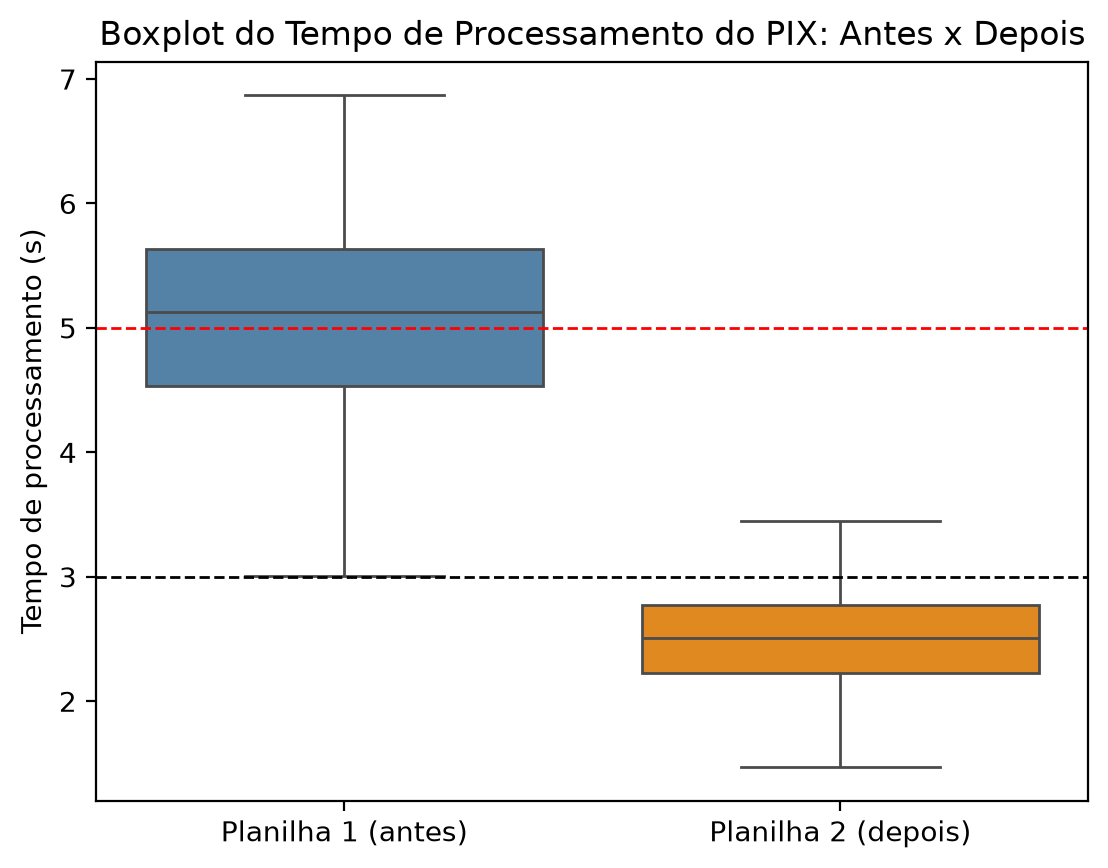

In [14]:
dados = pd.DataFrame({
    'Cenário': ['Planilha 1 (antes)']*len(df_antes) + ['Planilha 2 (depois)']*len(df),
    'Tempo (s)': list(df_antes[coluna]) + list(df[coluna])
})
sns.boxplot(data=dados, x='Cenário', y='Tempo (s)', hue='Cenário', palette=['steelblue', 'darkorange'])
plt.axhline(3, color='black', linestyle='--', linewidth=1)
plt.axhline(5, color='red', linestyle='--', linewidth=1)
plt.title('Boxplot do Tempo de Processamento do PIX: Antes x Depois')
plt.xlabel('')
plt.ylabel('Tempo de processamento (s)')
plt.show()

### Análise preliminar

- **Critério 1 (até 3 s):** antes, praticamente nenhum pagamento chegava na meta ideal (0,48% pelo modelo normal e 0 de 100 nos dados). Depois, 89% dos pagamentos (267 de 300) foram processados em até 3 s.
- **Critério 2 (entre 2 s e 4 s):** a proporção de pagamentos na faixa do mercado passou de cerca de 9% (8,76% pelo modelo e 9% nos dados) para 90,33%.

Além disso, a média caiu de 5,10 s para 2,51 s (mais ou menos 51% a menos), o desvio padrão caiu pela metade (de 0,81 s para 0,40 s) e nenhum pagamento passou do limite de 5 s (antes eram 56%).

**Conclusão preliminar:** os dois critérios mostram uma mudança grande e no sentido do objetivo, então há fortes indícios de que a reestruturação do processamento do PIX funcionou. Mas essa conclusão ainda é preliminar e precisa ser confirmada com as ferramentas de inferência estatística da próxima Sprint.